# Exploratory Data Analysis

This notebook validates and explores the three raw datasets used by the weekly sector-rotation strategy. The goal is to understand coverage, data quality, return behavior, cross-sector relationships, volatility, liquidity, and whether the Fear & Greed Index may add useful market-regime information.

**Important:** the downloaded OHLC `Close` values are split/dividend-adjusted prices. The wide `adj_close.csv` files are therefore used for cross-ticker price and return analysis.

## ETF Universe

The strategy rotates across the nine core Select Sector SPDR ETFs, using SPY as the broad-market benchmark. Each sector ETF provides targeted exposure to a major segment of the S&P 500.

| Ticker | Sector | Description |
|:--|:--|:--|
| **SPY** | Broad-market benchmark | Tracks the S&P 500 and represents large-cap U.S. equities across all eleven sectors; used to compare sector performance with the wider market. |
| **XLB** | Materials | Chemical producers, metals and mining companies, construction-material manufacturers, containers and packaging firms, and paper/forest-product companies. |
| **XLE** | Energy | Integrated oil and gas companies, exploration and production firms, refiners, pipeline operators, and energy-equipment and services providers. |
| **XLF** | Financials | Banks, insurance companies, capital-markets firms, consumer-finance providers, financial-services companies, and mortgage REITs. |
| **XLI** | Industrials | Aerospace and defense, machinery, transportation, logistics, electrical equipment, construction and engineering, and commercial-services companies. |
| **XLK** | Information Technology | Software, semiconductors, technology hardware, IT services, communications equipment, and electronic-component companies. |
| **XLP** | Consumer Staples | Food, beverage, tobacco, household-product, personal-care, and essential-retail companies whose demand tends to be relatively defensive. |
| **XLU** | Utilities | Electric, gas, water, independent power, renewable-electricity, and multi-utility companies. |
| **XLV** | Healthcare | Pharmaceuticals, biotechnology, medical devices and supplies, healthcare providers, managed-care companies, and life-sciences tools and services. |
| **XLY** | Consumer Discretionary | Retailers, automobile manufacturers, hotels and restaurants, household durables, leisure businesses, and other companies tied to non-essential consumer spending. |

In [2]:
from pathlib import Path
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yaml
from IPython.display import display

warnings.filterwarnings('ignore', category=FutureWarning)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.figsize': (14, 7), 'axes.titlesize': 13, 'axes.labelsize': 11})

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'config.yaml').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

CONFIG_PATH = PROJECT_ROOT / 'config.yaml'
with CONFIG_PATH.open() as file:
    CONFIG = yaml.safe_load(file) or {}

DATA_START_DATE = pd.Timestamp(CONFIG['data']['start_date'])
DATA_END_DATE = pd.Timestamp(CONFIG['data']['end_date'])

DATA_ROOT = PROJECT_ROOT / 'data'
DAILY_DIR = DATA_ROOT / 'stocks_daily' / 'raw'
WEEKLY_DIR = DATA_ROOT / 'stocks_weekly' / 'raw'
FG_PATH = DATA_ROOT / 'fear_and_greed_index' / 'fear-greed.csv'
TICKERS = ['XLB', 'XLE', 'XLF', 'XLI', 'XLK', 'XLP', 'XLU', 'XLV', 'XLY', 'SPY']
SECTORS = [ticker for ticker in TICKERS if ticker != 'SPY']

assert DAILY_DIR.exists(), f'Missing directory: {DAILY_DIR.resolve()}'
assert WEEKLY_DIR.exists(), f'Missing directory: {WEEKLY_DIR.resolve()}'
assert FG_PATH.exists(), f'Missing file: {FG_PATH.resolve()}'

In [3]:
def load_ohlcv_folder(folder):
    frames = {}
    for ticker in TICKERS:
        path = folder / f'{ticker}.csv'
        df = pd.read_csv(path, parse_dates=['Date']).sort_values('Date')
        df = df.drop_duplicates('Date', keep='last').set_index('Date')
        frames[ticker] = df
    return frames


def load_adjusted_close(folder):
    df = pd.read_csv(folder / 'adj_close.csv', parse_dates=['Date'])
    return df.sort_values('Date').drop_duplicates('Date', keep='last').set_index('Date')[TICKERS]


def coverage_table(frames):
    rows = []
    for ticker, df in frames.items():
        rows.append({
            'Ticker': ticker,
            'Start': df.index.min().date(),
            'End': df.index.max().date(),
            'Rows': len(df),
        })
    return pd.DataFrame(rows).set_index('Ticker').sort_index()


def plot_small_multiples(series_by_ticker, title, ylabel, color='tab:blue', ncols=3):
    n = len(series_by_ticker)
    nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3.2 * nrows), sharex=False)
    axes = np.atleast_1d(axes).ravel()
    for ax, (ticker, series) in zip(axes, series_by_ticker.items()):
        series.dropna().plot(ax=ax, lw=1, color=color)
        ax.set_title(ticker)
        ax.set_xlabel('')
        ax.set_ylabel(ylabel)
    for ax in axes[n:]:
        ax.set_visible(False)
    fig.suptitle(title, y=1.01, fontsize=16)
    fig.tight_layout()
    plt.show()

# Section 1 — Stocks Daily

Daily data supports data-quality checks and reveals high-frequency return, volatility, and liquidity behavior. Although the model trades weekly, daily observations help detect anomalies that weekly aggregation could hide.

In [4]:
daily = load_ohlcv_folder(DAILY_DIR)
daily_adj = load_adjusted_close(DAILY_DIR)
daily_returns = daily_adj.pct_change(fill_method=None)
print(f'Loaded {len(daily)} daily ticker files and a {daily_adj.shape[0]:,} × {daily_adj.shape[1]} adjusted-close panel.')

Loaded 10 daily ticker files and a 5,535 × 10 adjusted-close panel.


## Coverage, missing values, and trading-calendar gaps

First we verify each ticker's usable history and compare its dates with SPY's observed trading sessions. Using SPY as the reference avoids incorrectly labeling weekends and market holidays as gaps.

In [5]:
display(coverage_table(daily))

print('Missing adjusted-close observations by ticker:')
display(daily_adj.isna().sum().sort_values(ascending=False).to_frame('Missing rows'))

,Start,End,Rows
Ticker,,,
SPY,2004-01-02,2025-12-31,5535
XLB,2004-01-02,2025-12-31,5535
XLE,2004-01-02,2025-12-31,5535
XLF,2004-01-02,2025-12-31,5535
XLI,2004-01-02,2025-12-31,5535
XLK,2004-01-02,2025-12-31,5535
XLP,2004-01-02,2025-12-31,5535
XLU,2004-01-02,2025-12-31,5535
XLV,2004-01-02,2025-12-31,5535


Missing adjusted-close observations by ticker:


,Missing rows
XLB,0
XLE,0
XLF,0
XLI,0
XLK,0
XLP,0
XLU,0
XLV,0
XLY,0
SPY,0


## Adjusted close history — all tickers

This chart compares long-run price paths. It is useful for spotting discontinuities and structural differences, but raw price levels are not directly comparable because each ETF starts at a different level.

In [ ]:
ax = daily_adj.plot(figsize=(16, 8), lw=1, alpha=0.9)
ax.set(title='Daily Adjusted Close History', xlabel='', ylabel='Adjusted close (USD)')
ax.legend(ncol=3, bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

## Individual ticker close-price histories

Small multiples make ticker-specific gaps and regime changes easier to see than the combined chart. These plots also prevent high-priced ETFs from visually dominating lower-priced ETFs.

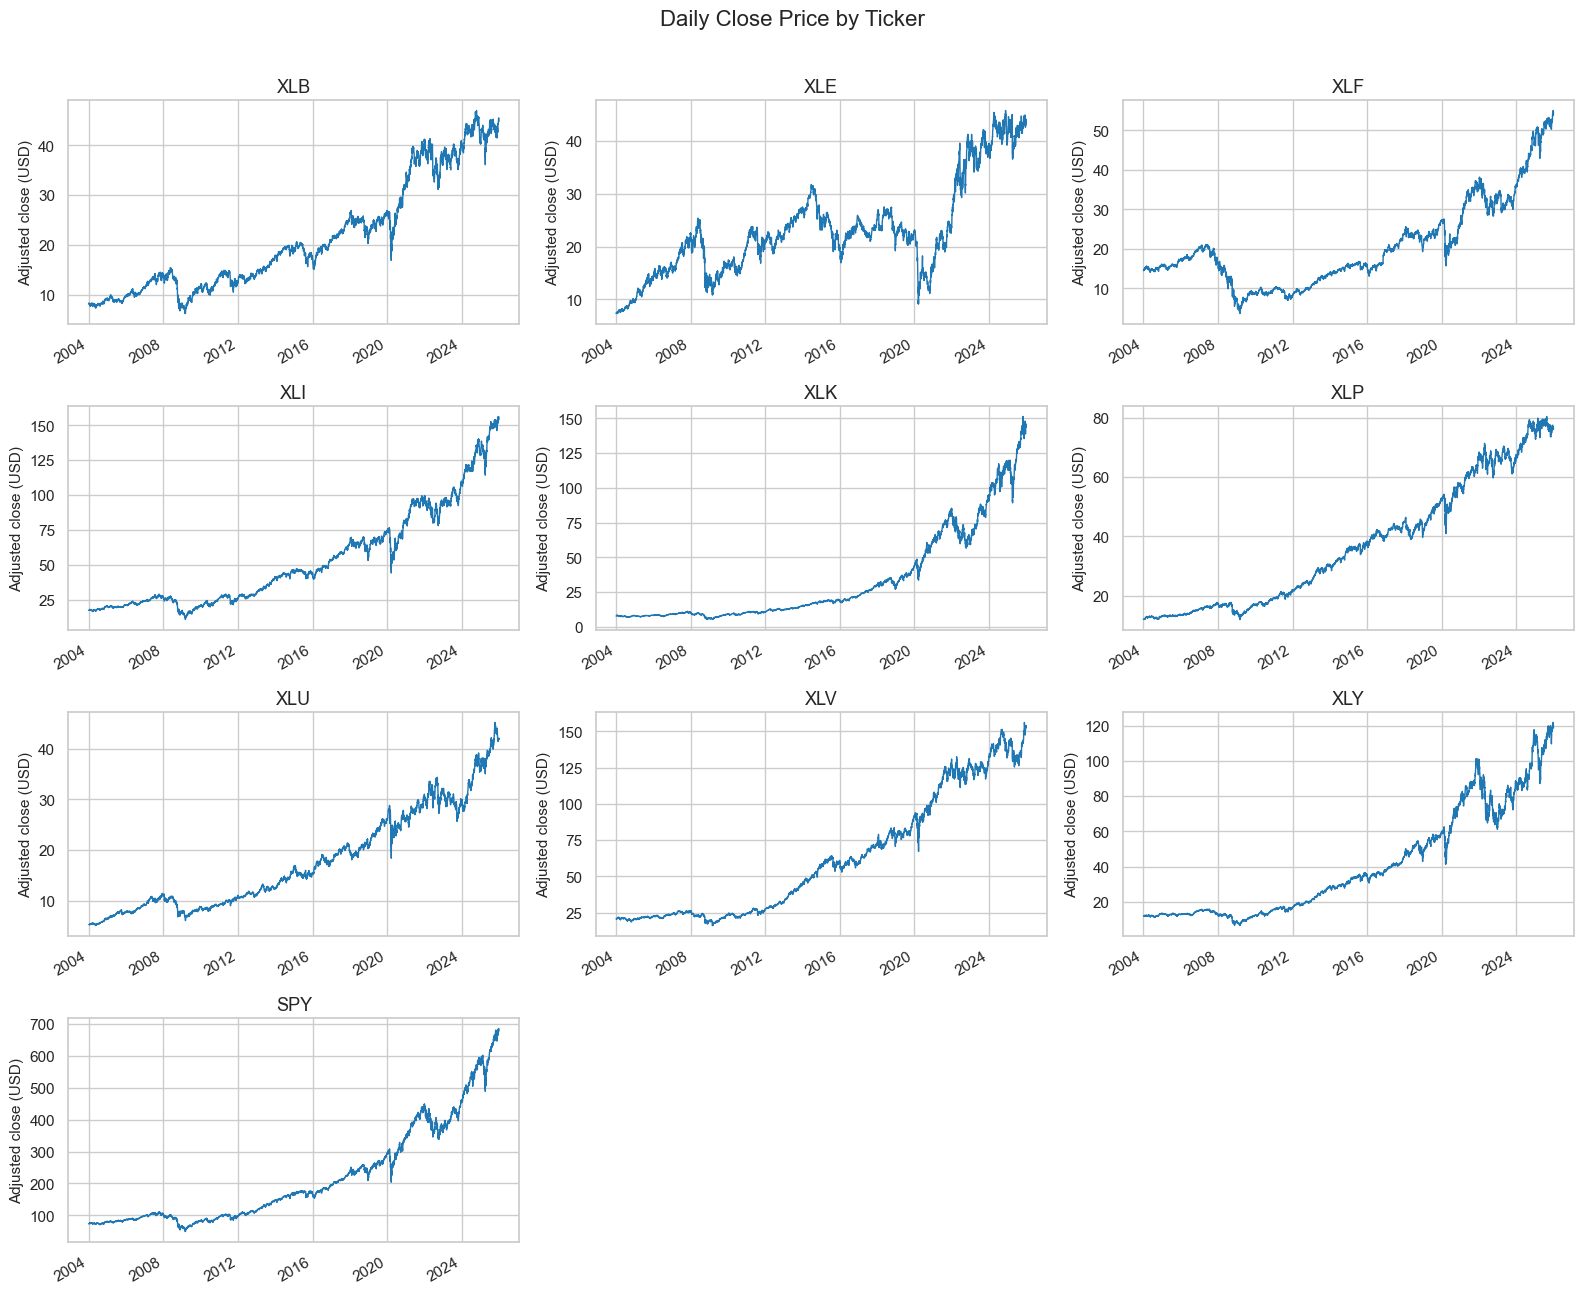

In [ ]:
plot_small_multiples(
    {ticker: daily[ticker]['Close'] for ticker in TICKERS},
    'Daily Close Price by Ticker', 'Adjusted close (USD)'
)

## Daily return distributions by sector

The model ultimately predicts future returns, so we inspect their shape. Wide tails and asymmetry matter because they make mean-squared-error models and Gaussian risk assumptions less reliable. SPY is omitted here to focus on sector behavior.

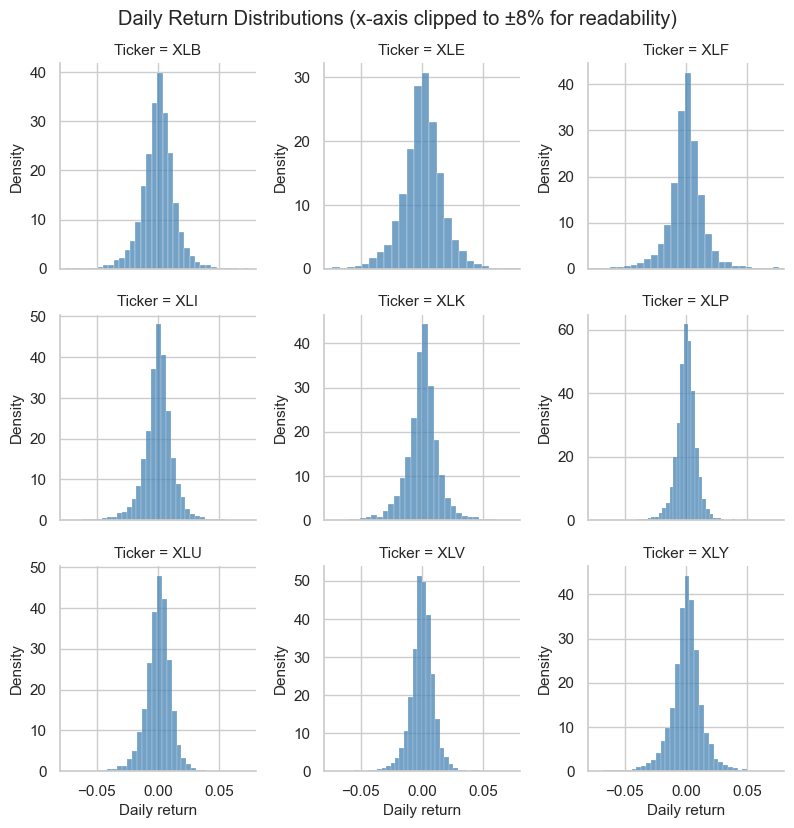

,count,mean,std,min,1%,5%,50%,95%,99%,max
XLB,5534.0,0.000414,0.014516,-0.124121,-0.041537,-0.022100,0.000834,0.021169,0.037731,0.140577
XLE,5534.0,0.000497,0.018565,-0.201412,-0.048754,-0.027895,0.000878,0.027449,0.045221,0.164747
XLF,5534.0,0.000401,0.018039,-0.166667,-0.051916,-0.023731,0.000674,0.022238,0.054829,0.164619
XLI,5534.0,0.000477,0.012947,-0.113441,-0.037303,-0.019547,0.000854,0.018890,0.034651,0.126512
XLK,5534.0,0.000627,0.013982,-0.138140,-0.040702,-0.021638,0.001129,0.020123,0.036990,0.138983
XLP,5534.0,0.000372,0.008768,-0.093956,-0.024420,-0.012744,0.000623,0.012684,0.020848,0.085107
XLU,5534.0,0.000439,0.011602,-0.113577,-0.031695,-0.016988,0.001004,0.015718,0.026751,0.127935
XLV,5534.0,0.000416,0.010401,-0.098611,-0.028659,-0.015667,0.000613,0.015069,0.025491,0.120547
XLY,5534.0,0.000509,0.013639,-0.126686,-0.038552,-0.021056,0.000984,0.020178,0.037818,0.108880


In [ ]:
long_daily_returns = (
    daily_returns[SECTORS].stack().rename('Return').reset_index()
    .rename(columns={'level_1': 'Ticker'})
)
g = sns.FacetGrid(long_daily_returns, col='Ticker', col_wrap=3, sharex=True, sharey=False, height=2.7)
g.map_dataframe(sns.histplot, x='Return', bins=60, stat='density', color='steelblue', alpha=0.75)
g.set(xlim=(-0.08, 0.08), xlabel='Daily return', ylabel='Density')
g.fig.suptitle('Daily Return Distributions (x-axis clipped to ±8% for readability)', y=1.02)
plt.show()

display(daily_returns[SECTORS].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).T)

## Correlation of daily returns

Sector rotation depends on relative movement. High correlation means less diversification, while lower-correlation sectors may carry distinct signals.

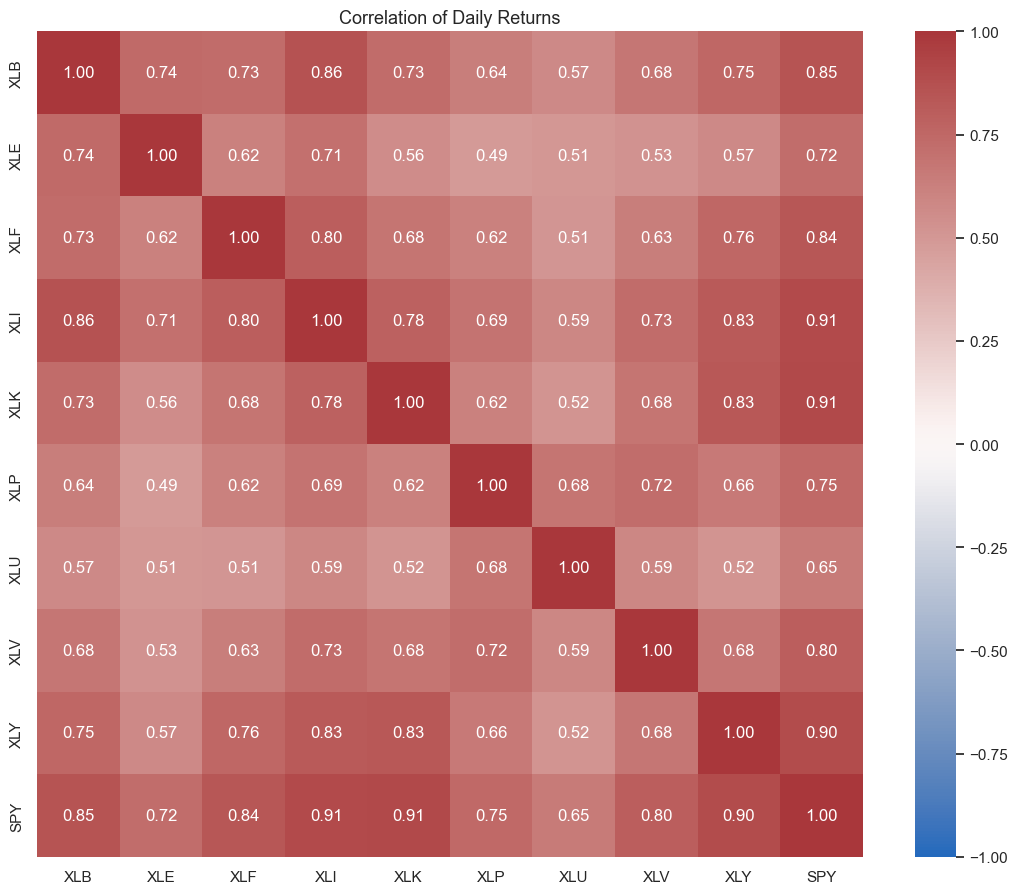

In [ ]:
plt.figure(figsize=(11, 9))
sns.heatmap(daily_returns.corr(), cmap='vlag', center=0, vmin=-1, vmax=1, annot=True, fmt='.2f', square=True)
plt.title('Correlation of Daily Returns')
plt.tight_layout()
plt.show()

## Rolling 52-week volatility

Daily volatility is annualized from a rolling 252-trading-day standard deviation. Volatility regimes can influence position sizing and may serve as predictive features or risk controls.

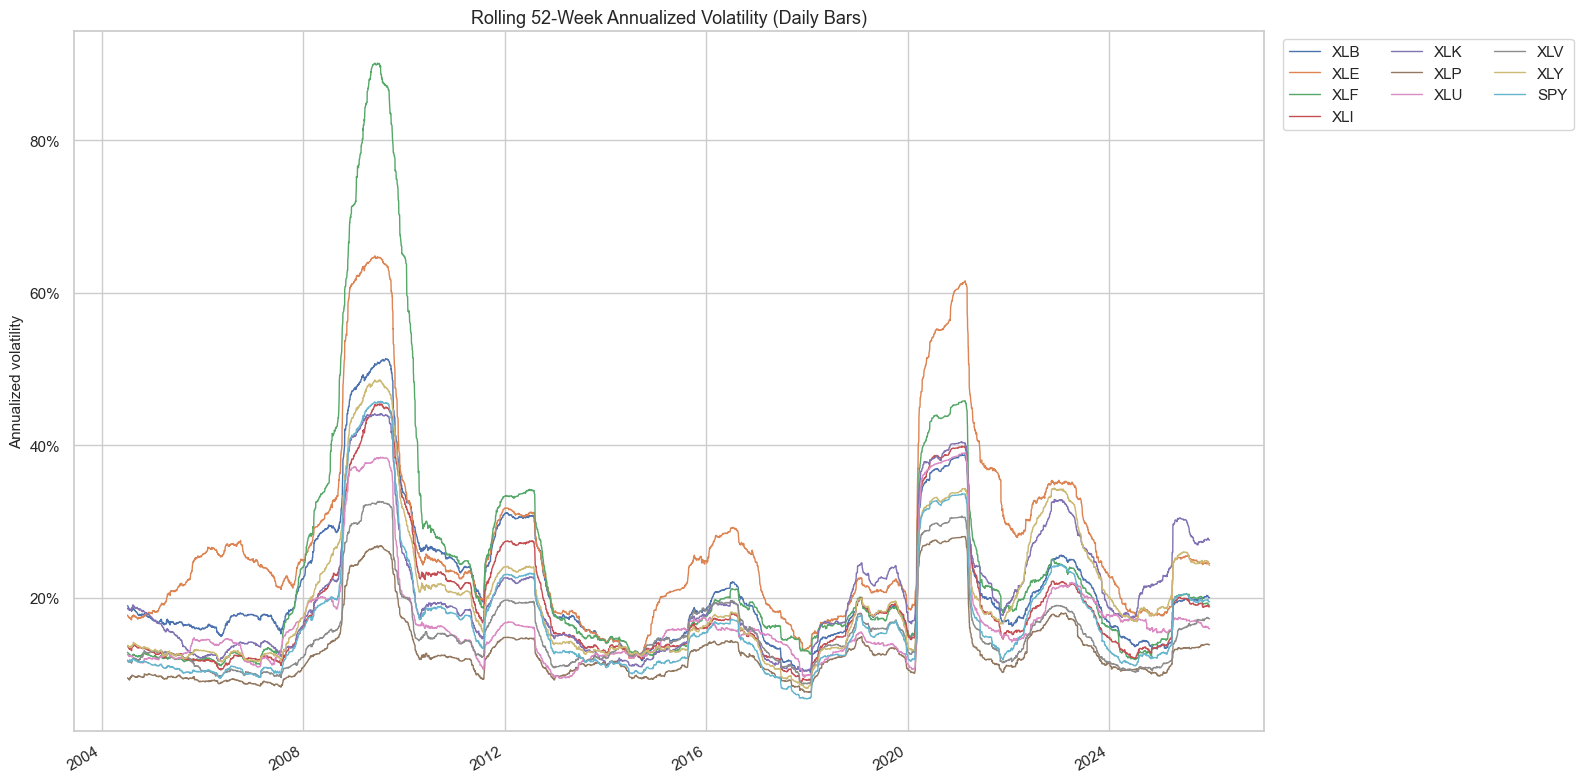

In [ ]:
daily_vol_52w = daily_returns.rolling(252, min_periods=126).std() * np.sqrt(252)
ax = daily_vol_52w.plot(figsize=(16, 8), lw=1)
ax.set(title='Rolling 52-Week Annualized Volatility (Daily Bars)', xlabel='', ylabel='Annualized volatility')
ax.yaxis.set_major_formatter(lambda x, pos: f'{x:.0%}')
ax.legend(ncol=3, bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

## Trading volume over time

Volume is a practical liquidity indicator. Small multiples preserve each ETF's scale and expose shifts that could affect slippage, transaction costs, or the reliability of historical signals.

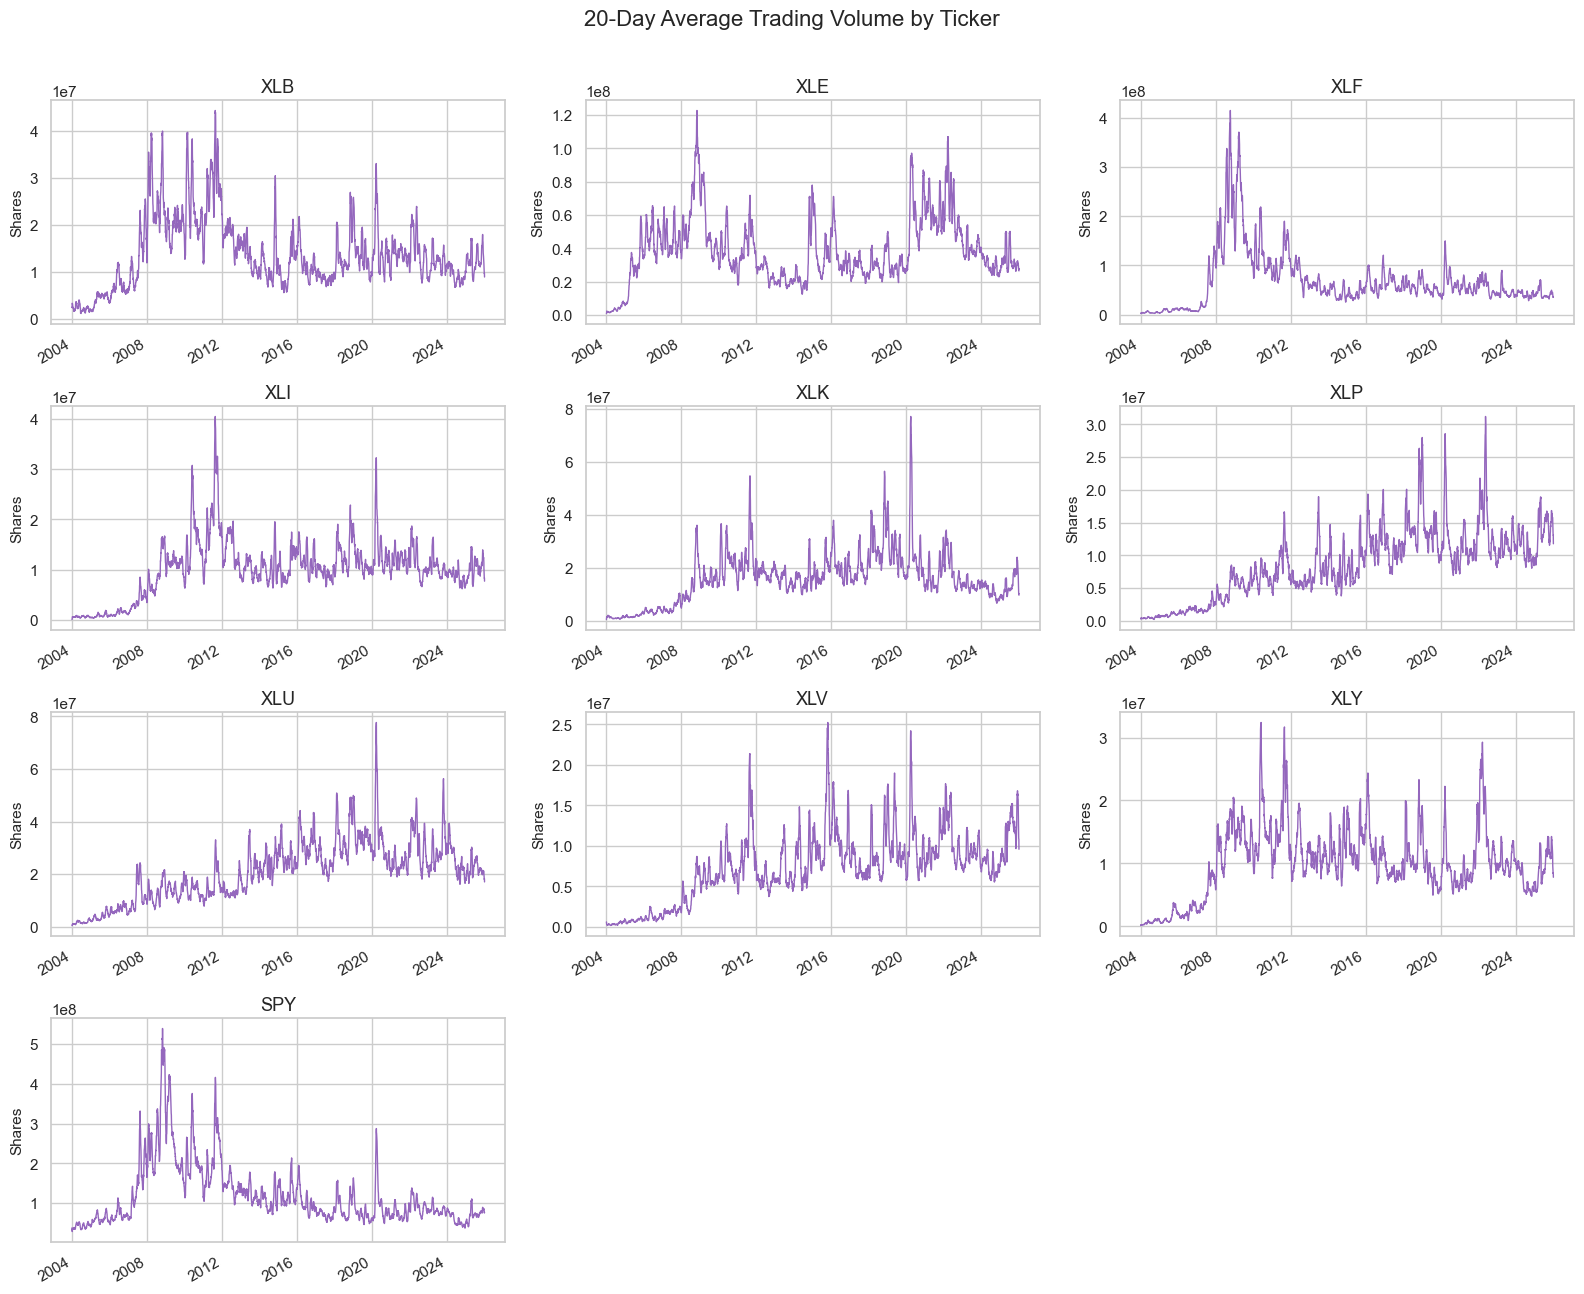

In [ ]:
plot_small_multiples(
    {ticker: daily[ticker]['Volume'].rolling(20, min_periods=1).mean() for ticker in TICKERS},
    '20-Day Average Trading Volume by Ticker', 'Shares', color='tab:purple'
)

# Section 2 — Stocks Weekly

Weekly Friday-close bars match the strategy's rebalance horizon. This section checks whether aggregation is complete and examines the return and risk structure the model will see directly.

In [ ]:
weekly = load_ohlcv_folder(WEEKLY_DIR)
weekly_adj = load_adjusted_close(WEEKLY_DIR)
weekly_returns = weekly_adj.pct_change(fill_method=None)
print(f'Loaded {len(weekly)} weekly ticker files and a {weekly_adj.shape[0]:,} × {weekly_adj.shape[1]} adjusted-close panel.')

Loaded 10 weekly ticker files and a 1,149 × 10 adjusted-close panel.


## Coverage, missing values, and weekly-calendar gaps

In [ ]:
display(coverage_table(weekly))
print('Missing adjusted-close observations by ticker:')
display(weekly_adj.isna().sum().sort_values(ascending=False).to_frame('Missing rows'))

,Start,End,Rows
Ticker,,,
SPY,2004-01-02,2026-01-02,1149
XLB,2004-01-02,2026-01-02,1149
XLE,2004-01-02,2026-01-02,1149
XLF,2004-01-02,2026-01-02,1149
XLI,2004-01-02,2026-01-02,1149
XLK,2004-01-02,2026-01-02,1149
XLP,2004-01-02,2026-01-02,1149
XLU,2004-01-02,2026-01-02,1149
XLV,2004-01-02,2026-01-02,1149


Missing adjusted-close observations by ticker:


,Missing rows
XLB,0
XLE,0
XLF,0
XLI,0
XLK,0
XLP,0
XLU,0
XLV,0
XLY,0
SPY,0


## Weekly adjusted close history

The combined weekly price chart is the direct price input view for the strategy. We look for discontinuities and implausible jumps.

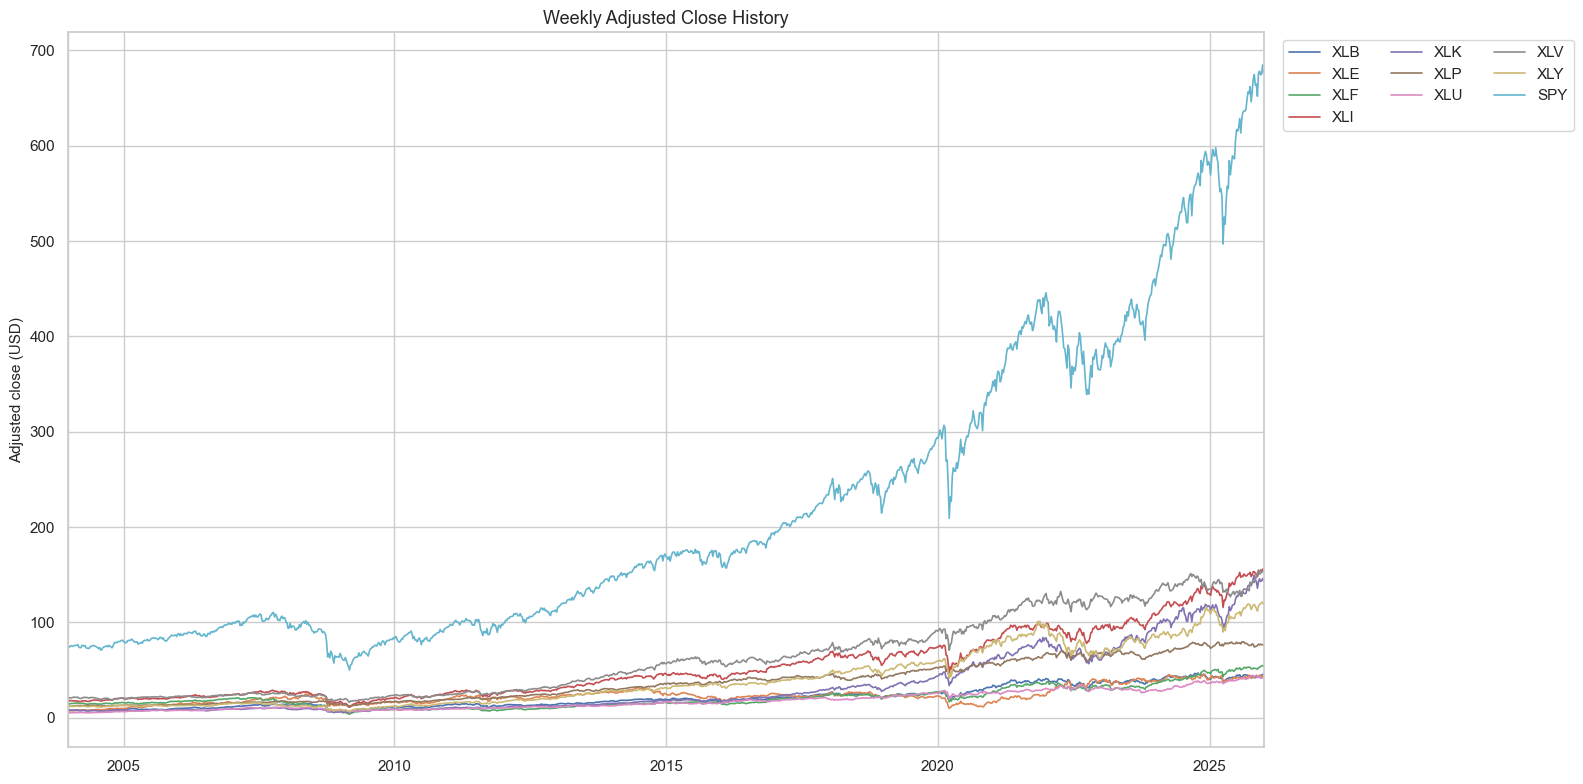

In [ ]:
ax = weekly_adj.plot(figsize=(16, 8), lw=1.2)
ax.set(title='Weekly Adjusted Close History', xlabel='', ylabel='Adjusted close (USD)')
ax.legend(ncol=3, bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

## Weekly return distributions

Weekly returns are closer to the prediction target than daily returns. Their tails show the scale of unusual outcomes the model and portfolio risk controls must tolerate.

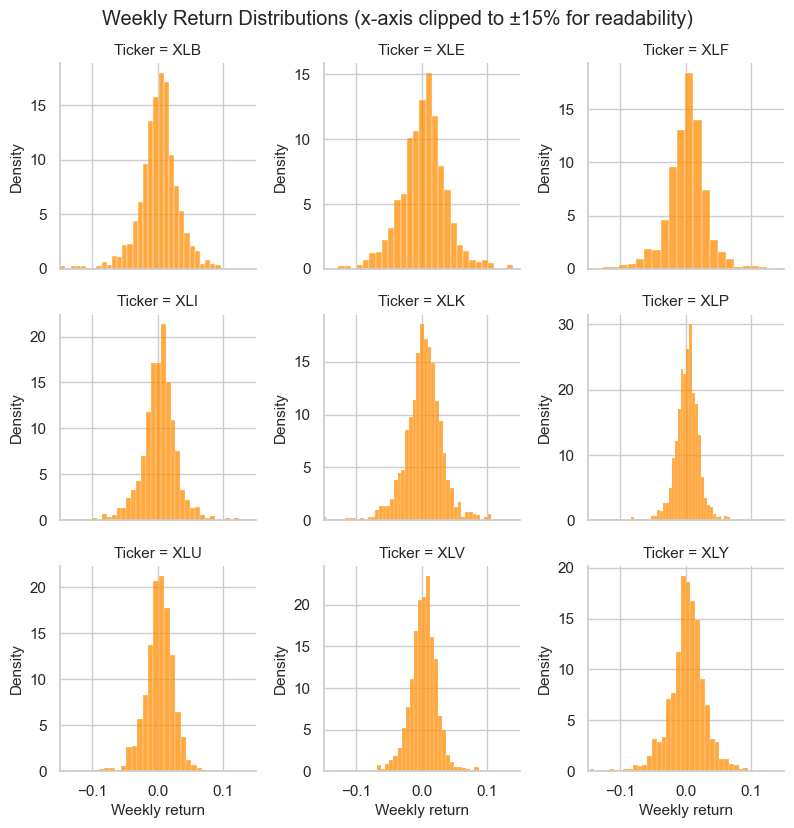

,count,mean,std,min,1%,5%,50%,95%,99%,max
XLB,1148.0,0.001958,0.030636,-0.149388,-0.084228,-0.047014,0.003145,0.047233,0.078766,0.206759
XLE,1148.0,0.002303,0.038199,-0.251853,-0.098093,-0.056492,0.004610,0.056876,0.101008,0.177547
XLF,1148.0,0.001815,0.036632,-0.239592,-0.099947,-0.053823,0.003635,0.048617,0.100182,0.325243
XLI,1148.0,0.002295,0.028201,-0.183349,-0.080343,-0.042528,0.003573,0.042649,0.072927,0.154615
XLK,1148.0,0.002946,0.027971,-0.151681,-0.068234,-0.042106,0.003560,0.044203,0.079409,0.106138
XLP,1148.0,0.001773,0.018013,-0.133309,-0.046464,-0.025399,0.002774,0.026751,0.045282,0.067787
XLU,1148.0,0.002098,0.024483,-0.198007,-0.069369,-0.036831,0.003655,0.036045,0.054488,0.176023
XLV,1148.0,0.001993,0.022165,-0.185835,-0.056287,-0.031974,0.003034,0.034387,0.060200,0.092763
XLY,1148.0,0.002434,0.029242,-0.147206,-0.079233,-0.045108,0.002985,0.045414,0.075409,0.183316


In [ ]:
long_weekly_returns = weekly_returns[SECTORS].stack().rename('Return').reset_index().rename(columns={'level_1': 'Ticker'})
g = sns.FacetGrid(long_weekly_returns, col='Ticker', col_wrap=3, sharex=True, sharey=False, height=2.7)
g.map_dataframe(sns.histplot, x='Return', bins=45, stat='density', color='darkorange', alpha=0.75)
g.set(xlim=(-0.15, 0.15), xlabel='Weekly return', ylabel='Density')
g.fig.suptitle('Weekly Return Distributions (x-axis clipped to ±15% for readability)', y=1.02)
plt.show()

display(weekly_returns[SECTORS].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).T)

## Correlation of weekly returns

Weekly correlation indicates how much independent cross-sectional information is available at the trading horizon. Strong common movement makes ranking sectors more important than predicting the market direction alone.

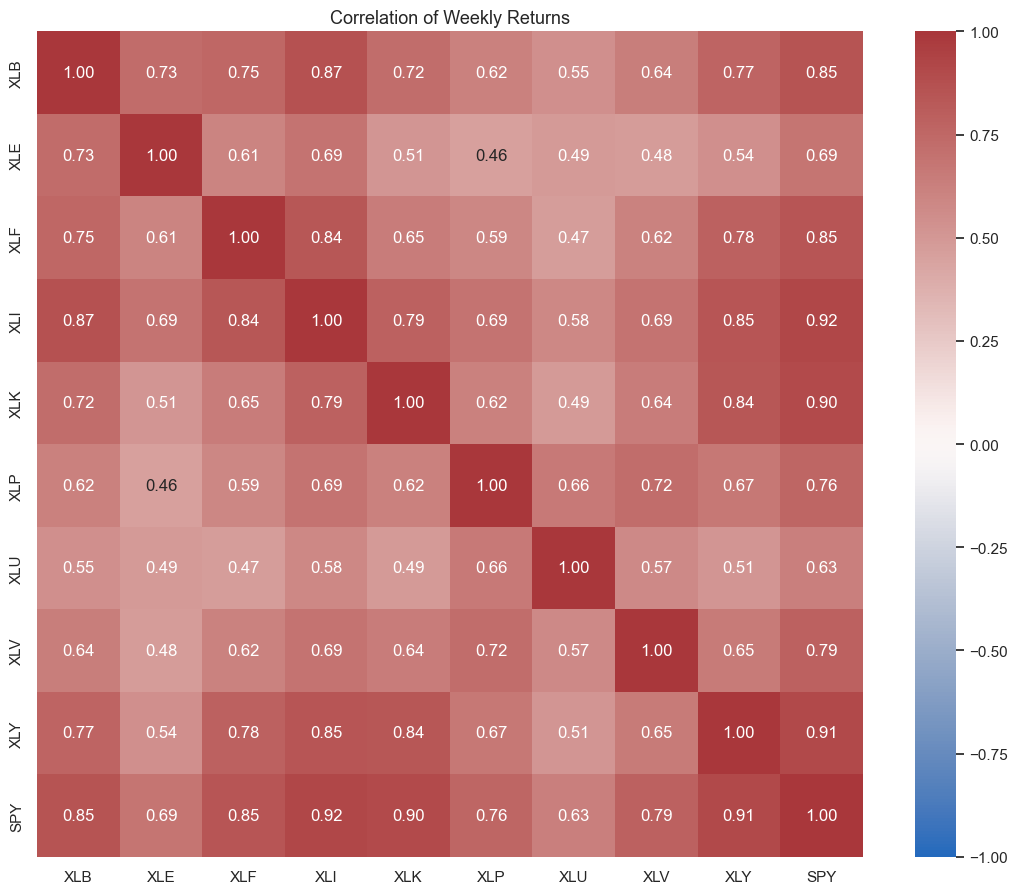

In [ ]:
plt.figure(figsize=(11, 9))
sns.heatmap(weekly_returns.corr(), cmap='vlag', center=0, vmin=-1, vmax=1, annot=True, fmt='.2f', square=True)
plt.title('Correlation of Weekly Returns')
plt.tight_layout()
plt.show()

## Rolling 52-week volatility on weekly bars

A rolling standard deviation over 52 weekly returns is annualized by √52. This gives a horizon-consistent view of changing sector risk.

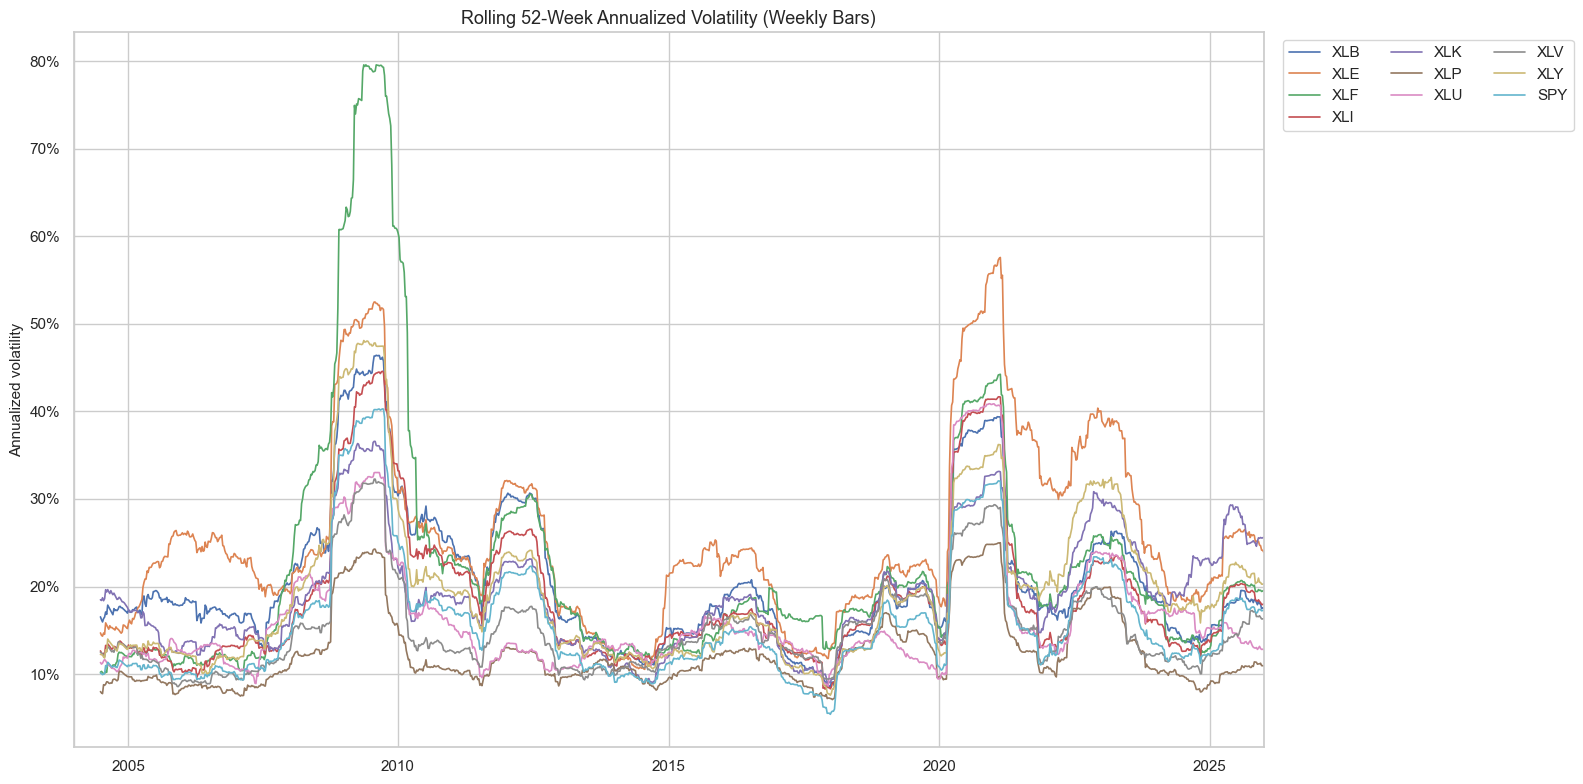

In [ ]:
weekly_vol_52w = weekly_returns.rolling(52, min_periods=26).std() * np.sqrt(52)
ax = weekly_vol_52w.plot(figsize=(16, 8), lw=1.2)
ax.set(title='Rolling 52-Week Annualized Volatility (Weekly Bars)', xlabel='', ylabel='Annualized volatility')
ax.yaxis.set_major_formatter(lambda x, pos: f'{x:.0%}')
ax.legend(ncol=3, bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Section 3 — Fear and Greed Index

The Fear & Greed Index summarizes market sentiment on a 0–100 scale. For sector rotation, it may help identify risk-on/risk-off regimes, but its later start date limits the common sample to 2011 onward.

In [ ]:
fear_greed = pd.read_csv(FG_PATH, parse_dates=['Date']).sort_values('Date')
fear_greed = fear_greed.drop_duplicates('Date', keep='last').set_index('Date')
fear_greed['Fear Greed'] = pd.to_numeric(fear_greed['Fear Greed'], errors='coerce')
fear_greed['Rating'] = fear_greed['Rating'].astype('string').str.strip().str.title()
fear_greed = fear_greed.loc[DATA_START_DATE:DATA_END_DATE]

summary = pd.DataFrame({
    'Start': [fear_greed.index.min().date()],
    'End': [fear_greed.index.max().date()],
    'Rows': [len(fear_greed)],
    'Duplicate dates': [int(fear_greed.index.duplicated().sum())],
    'Missing score': [int(fear_greed['Fear Greed'].isna().sum())],
    'Missing rating': [int(fear_greed['Rating'].isna().sum())],
})
display(summary)
display(fear_greed.describe(include='all'))

## Distribution of index scores

The histogram and density estimate show which sentiment states are common or rare. If extremes are sparse, models may need careful regularization and time-aware validation to avoid overfitting them.

In [ ]:
plt.figure(figsize=(12, 6))
sns.histplot(fear_greed['Fear Greed'].dropna(), bins=30, kde=True, color='slateblue')
plt.title('Distribution of Fear & Greed Scores')
plt.xlabel('Fear & Greed score (0–100)')
plt.ylabel('Observations')
plt.tight_layout()
plt.show()

## Distribution of rating categories

Category counts reveal class balance. This matters if ratings are encoded as categorical model features or used to define sentiment regimes.

In [ ]:
rating_order = ['Extreme Fear', 'Fear', 'Neutral', 'Greed', 'Extreme Greed']
rating_counts = fear_greed['Rating'].value_counts().reindex(rating_order).fillna(0)
plt.figure(figsize=(10, 5))
sns.barplot(x=rating_counts.index, y=rating_counts.values, hue=rating_counts.index, palette='RdYlGn', legend=False)
plt.title('Fear & Greed Rating Counts')
plt.xlabel('Rating')
plt.ylabel('Observations')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()
display(rating_counts.to_frame('Count'))

## Index value over time with rating zones

Colored background bands translate the numeric score into the conventional sentiment zones. This view helps identify persistence, abrupt regime changes, and long periods near extremes.

In [ ]:
fig, ax = plt.subplots(figsize=(16, 7))
zones = [
    (0, 25, '#d73027', 'Extreme Fear'), (25, 45, '#fc8d59', 'Fear'),
    (45, 55, '#fee08b', 'Neutral'), (55, 75, '#91cf60', 'Greed'),
    (75, 100, '#1a9850', 'Extreme Greed')
]
for low, high, color, label in zones:
    ax.axhspan(low, high, color=color, alpha=0.18, label=label)
ax.plot(fear_greed.index, fear_greed['Fear Greed'], color='black', lw=0.8)
ax.set(title='Fear & Greed Index Through Time', xlabel='', ylabel='Index score', ylim=(0, 100))
ax.legend(ncol=5, loc='upper center', bbox_to_anchor=(0.5, 1.13))
plt.tight_layout()
plt.show()

## Weekly average

A weekly average smooths daily noise may be more appropriate for a weekly strategy than the raw daily value.

In [ ]:
fear_greed['Rolling Weekly'] = fear_greed['Fear Greed'].rolling(7, min_periods=7).mean()
fig, ax = plt.subplots(figsize=(16, 7))
ax.plot(fear_greed.index, fear_greed['Fear Greed'], color='lightgray', lw=0.8, label='Fear Greed')
ax.plot(fear_greed.index, fear_greed['Rolling Weekly'], color='navy', lw=2, label='Rolling Weekly')
ax.set(title='Fear & Greed Index and Rolling Weekly Average', xlabel='', ylabel='Index score', ylim=(0, 100))
ax.legend()
plt.tight_layout()
plt.show()

## Alignment with SPY performance

The final chart aligns sentiment with SPY over their overlapping dates. SPY is rebased to 100 at the start of the overlap, while sentiment remains on its 0–100 scale. The dual axes compare timing and regimes—not equal percentage changes or causality.

In [ ]:
spy = daily_adj['SPY'].dropna().rename('SPY')
aligned = pd.concat([fear_greed['Fear Greed'], spy], axis=1, join='inner').dropna()
aligned['SPY (start=100)'] = aligned['SPY'] / aligned['SPY'].iloc[0] * 100

fig, ax1 = plt.subplots(figsize=(16, 7))
ax2 = ax1.twinx()
ax1.plot(aligned.index, aligned['SPY (start=100)'], color='navy', lw=1.5, label='SPY (start = 100)')
ax2.plot(aligned.index, aligned['Fear Greed'], color='darkorange', lw=0.8, alpha=0.7, label='Fear & Greed')
ax1.set(title=f'SPY Performance vs Fear & Greed ({aligned.index.min():%Y-%m-%d} to {aligned.index.max():%Y-%m-%d})', xlabel='', ylabel='SPY indexed level', ylim=(0, None))
ax2.set(ylabel='Fear & Greed score', ylim=(0, 100))
lines = ax1.get_lines() + ax2.get_lines()
ax1.legend(lines, [line.get_label() for line in lines], loc='upper left')
plt.tight_layout()
plt.show()

print(f'Overlapping observations: {len(aligned):,}')